# 02 — Preprocessing & Feature Engineering

Component 3 (Learning Insight & Early Warning System) — Grade 2-3 mathematics dyscalculia,
synthetic research data.

**Purpose of this notebook:** turn the 23 model-role raw features NB01 verified into a modelling-
ready matrix — drop dead columns, handle missingness with indicator+imputation (never listwise
deletion, never a zero-imputed slope), engineer cross-`t` lag/delta features, run diagnostic PCA,
and persist a TRAIN-only-fitted `sklearn` `Pipeline` plus the engineered matrix for NB03 onward.

This notebook does **not** model, evaluate, or touch `population`/`dd_subtype`. NB03 owns the
leakage audit (SF-038) and must re-run it on everything engineered here — see the Findings cell
at the end.

Primary arm: **h=5, n=4** (`training_table_seed20260828_n300_h5_sweepn4.csv`), the same file NB01
used. All splitting uses the `split` column already materialised in that file (grouped by
`student_id`, no leakage across train/test).

In [1]:
import sys
from pathlib import Path
NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

from nbconfig import *

np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Random seed:", RANDOM_SEED)

Random seed: 20260828


### Mutual information helper

Per-feature MI against the target, computed with the stock `sklearn.feature_selection.
mutual_info_classif` (single feature at a time, matching NB01's exact call pattern) so the numbers
in this notebook are directly comparable to NB01's baseline
(`outputs/tables/11_mutual_information_ranking.csv`).

In [2]:
def mi_ranking(frame, feats, target, random_state=RANDOM_SEED):
    rows = []
    for feat in feats:
        d = frame[[feat, target]].dropna()
        if len(d) < 10 or d[feat].nunique() < 2:
            rows.append({"feature": feat, "n_used": len(d), "mutual_info": np.nan})
            continue
        mi = mutual_info_classif(
            d[[feat]].values, d[target].values, discrete_features=False, random_state=random_state,
        )[0]
        rows.append({"feature": feat, "n_used": len(d), "mutual_info": mi})
    return pd.DataFrame(rows).sort_values("mutual_info", ascending=False).reset_index(drop=True)

print("mi_ranking ready (stock sklearn.mutual_info_classif, same call pattern as NB01).")

mi_ranking ready (stock sklearn.mutual_info_classif, same call pattern as NB01).


In [3]:
df_raw = pd.read_csv(TRAINING_TABLE_PATH)
print(df_raw.shape)
assert df_raw.shape[0] == 2700
assert "population" not in df_raw.columns and "dd_subtype" not in df_raw.columns
df_raw.head(3)

(2700, 52)


,student_id,t,sessions_observed,b_sessions_observed,c_sessions_observed,score_trend_slope,score_avg_recent,mastery_progression_rate,number_sense_mastery,weakest_skill_persistence,rt_change_ratio,rt_variability,rt_accuracy_tradeoff,game_latency_change_ratio,error_recurrence_rate,hint_avoidance,hint_intensity,guess_guard_rate,engagement_consistency,engagement_decline_rate,frustration_mean,frustration_slope,difficulty_floor_hits,stagnant_skill_count,slope_censored_count,number_sense_minus_operations,ipsatised_mastery_counting,ipsatised_mastery_number_sense,ipsatised_mastery_place_value,ipsatised_mastery_addition,ipsatised_mastery_subtraction,ipsatised_mastery_multiplication,ipsatised_mastery_division,evidence_status,trajectory_indicators,trajectory_indicators_status,future_stagnant_count,future_stagnant_skills,risk_level,risk_level_status,future_frustration_mean,future_engagement_decline_rate,teacher_facing_output,horizon,horizon_role,warmup_floor,stagnant_trailing_window_may_cross_t,target_window_first_session,target_window_last_session,future_sessions_scheduled,future_sessions_observed,split
0,STU-0001,3,3,3,3,-0.083333,0.361111,0.012129,0.319776,3,NaN,1.825620,2.34,NaN,0.5,0.0,0.222222,0.0,1.0,-0.080429,0.492655,0.701311,NaN,0,1,0.169776,0.057262,0.131936,-0.037840,-0.037840,-0.037840,-0.037840,-0.037840,sufficient_evidence,[],RULES_UNDEFINED,1,number_sense,NaN,CALIBRATION_PENDING,0.413283,-0.096328,flags learners for teacher review,5,primary,3,True,4,8,5,5,test
1,STU-0001,5,5,5,5,-0.075000,0.277778,-0.002424,0.296929,5,1.077998,0.566962,NaN,0.974352,0.5,0.0,0.266667,0.0,1.0,-0.031598,0.452969,0.038687,0.0,0,0,0.146929,0.124630,0.101669,-0.045260,-0.045260,-0.045260,-0.045260,-0.045260,sufficient_evidence,[],RULES_UNDEFINED,1,number_sense,NaN,CALIBRATION_PENDING,0.608352,-0.002269,flags learners for teacher review,5,primary,3,True,6,10,5,5,test
2,STU-0001,7,7,7,7,-0.011905,0.333333,-0.004615,0.341119,7,0.939686,0.115909,NaN,0.953031,0.5,0.0,0.250000,0.0,1.0,-0.031598,0.452969,0.038687,0.0,0,0,0.191119,0.184220,0.128563,-0.062557,-0.062557,-0.062557,-0.062557,-0.062557,sufficient_evidence,[],RULES_UNDEFINED,1,number_sense,NaN,CALIBRATION_PENDING,0.471940,0.005418,flags learners for teacher review,5,primary,3,True,8,12,5,5,test


## 0. Target column

NB01 used `future_stagnant_count` (0-3, the count of skills that trip the stagnation definition
within the `h=5` forecast horizon) as the modelling target throughout its MI ranking and boxplots.
This notebook reuses the same target for all MI comparisons so the numbers are comparable to
NB01's baseline. `future_stagnant_count` is itself out of scope to engineer — it is a label, not
a feature, and is excluded from every feature list below.

In [4]:
TARGET = "future_stagnant_count"
assert TARGET in df_raw.columns
df_raw[TARGET].value_counts().sort_index()

future_stagnant_count
0    1213
1    1326
2     156
3       5
Name: count, dtype: int64

## A. Drop what NB01 killed

**A1 — two dead constants.** `guess_guard_rate` (`0.0` on all 2,700 rows) and
`engagement_consistency` (`1.0` on every non-null row — it carries the same C-telemetry warm-up
nulls as `engagement_decline_rate`/`frustration_slope`, 221 rows null, resolving by `t≈11`, but
is otherwise a pure constant with zero variance) carried `NaN` mutual information in NB01
because MI is undefined against a constant, not because the computation failed. Both are
generator-side limitations of the synthetic C-telemetry substrate (the feature register already
flags every C-engagement feature as `SYNTHETIC-ONLY`) — a fact for the write-up, not a bug to
repair here. Dropped.

**A2 — three exact aliases of `t`.** `sessions_observed == b_sessions_observed ==
c_sessions_observed == t` on every single row (not merely correlated — identical), because every
learner attended every session in this synthetic cohort. This was the sole source of the
`|r| > 0.9` correlation pairs and the rank-deficient VIF matrix NB01 flagged. We keep
`sessions_observed` as the one clean time-index column and drop the other two aliases; it is
treated as a calendar index, not a measure of exposure.

Feature count: 23 model-role features → 19 after A1+A2.

In [5]:
DROP_CONST = ["guess_guard_rate", "engagement_consistency"]
DROP_TIME_ALIAS = ["b_sessions_observed", "c_sessions_observed"]

for c in DROP_CONST:
    assert df_raw[c].dropna().nunique() == 1, f"{c} is not constant on its non-null values — re-check before dropping"
for c in ["sessions_observed", "b_sessions_observed", "c_sessions_observed"]:
    assert (df_raw[c] == df_raw["t"]).all(), f"{c} is not an exact alias of t"

df = df_raw.drop(columns=DROP_CONST + DROP_TIME_ALIAS)

MODEL_FEATURES_19 = [f for f in MODEL_FEATURES if f not in DROP_CONST + DROP_TIME_ALIAS]
assert len(MODEL_FEATURES_19) == 19
print(f"Model features: {len(MODEL_FEATURES)} -> {len(MODEL_FEATURES_19)}")
MODEL_FEATURES_19

Model features: 23 -> 19


['score_trend_slope',
 'score_avg_recent',
 'mastery_progression_rate',
 'number_sense_mastery',
 'weakest_skill_persistence',
 'rt_change_ratio',
 'rt_variability',
 'rt_accuracy_tradeoff',
 'game_latency_change_ratio',
 'error_recurrence_rate',
 'hint_avoidance',
 'hint_intensity',
 'engagement_decline_rate',
 'frustration_mean',
 'frustration_slope',
 'difficulty_floor_hits',
 'stagnant_skill_count',
 'sessions_observed',
 'slope_censored_count']

## B. Null strategy (open decision 3-Q6 — proposal, not closure)

**No listwise deletion.** Only 1,260/2,700 rows (46.7%) are complete-case, and the incomplete
rows skew to early `t` — dropping them would discard over half the data and bias the model toward
late snapshots, exactly backwards for an early-warning system.

**The rule (doc 06 §5, binding):**
- Missingness is preserved, never repaired — every null gets an explicit indicator column.
- No carry-forward: a session's value is never copied into a session that did not happen.
- **A null is never imputed to `0.0` for a slope-type feature.** Zero means "flat", which is a
  strong claim in a system whose target *is* flatness. Slopes/rates imputed with the TRAIN
  median instead: `score_trend_slope`, `mastery_progression_rate`, `rt_change_ratio`,
  `game_latency_change_ratio`, `frustration_slope`.
- `hint_intensity` nulls are the one safe zero-impute: the feature is null **by definition** when
  the hint rate is exactly 0 (not from insufficient data), and `hint_avoidance` already carries
  that case (`hint_intensity` null ⟺ `hint_avoidance == 1`, verified P=1.000 in NB01). We impute
  `hint_intensity` to `0.0` and do **not** add a redundant indicator for it — the indicator would
  duplicate `hint_avoidance` exactly.

**Two distinct missingness mechanisms (NB01 §4), handled differently:**

| Feature | Mechanism | Treatment |
|---|---|---|
| `rt_change_ratio`, `game_latency_change_ratio` | structural warm-up: 100% null at `t=3`, 0% after — the indicator is bit-identical to `(t == 3)` | covered by the shared `is_first_snapshot` indicator (see below), not a per-feature one + TRAIN-median impute (slope-like, never 0) |
| `engagement_decline_rate`, `frustration_slope` | C-telemetry warm-up, decays ~0.50→0 by `t≈11`; the two indicators are perfectly correlated (r=1.0, verified below) | one shared `c_telemetry_missing` indicator (avoids a near-duplicate column) + per-feature TRAIN-median impute |
| `difficulty_floor_hits` | same warm-up family but resolves on a slower, only partially-overlapping schedule — its indicator correlates at just ~0.44 with the pair above, not ≈1.0 | own `difficulty_floor_hits_missing` indicator (kept separate, not folded into the shared one) + TRAIN-median impute |
| `frustration_mean`, `rt_variability` | ordinary sparse warm-up nulls | own indicator + TRAIN-median impute |
| `rt_accuracy_tradeoff` | **persistent, informative**: null 26-36% at every `t` including `t=19`, because it is undefined when `accuracy_rate == 0` — the child got nothing right in the window | own indicator, promoted to the first-class engineered feature `zero_accuracy_window` (§D) + TRAIN-median impute of the value |
| `hint_intensity` | null by definition when rate = 0 | impute to `0.0`, no indicator (redundant with `hint_avoidance`) |

**One shared `is_first_snapshot` indicator, not three near-duplicates.** `rt_change_ratio_missing`,
`game_latency_change_ratio_missing`, and the lag-feature null indicator (§D) are each individually
bit-identical to `(t == 3)` — every one of them is null on exactly the first snapshot for every
learner and nowhere else, positive rate `1/9 = 0.1111`. Building three separate columns for the
same deterministic function of `t` would not add information; it was corrected from an earlier
draft that built them separately after not noticing the equality. `is_first_snapshot` is built once
and reused for all three purposes (see §D for the lag-feature use).

All imputers are fit on the TRAIN split only (`split == "train"`) inside the `ColumnTransformer`
below, and applied unchanged to test.

In [6]:
null_counts = df[MODEL_FEATURES_19].isnull().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)
null_counts

difficulty_floor_hits        864
rt_accuracy_tradeoff         830
rt_change_ratio              300
game_latency_change_ratio    300
engagement_decline_rate      221
frustration_slope            221
frustration_mean              45
hint_intensity                10
rt_variability                 8
dtype: int64

In [7]:
# verify the two mechanisms
warmup_pair = ["rt_change_ratio", "game_latency_change_ratio"]
null_by_t = df.groupby("t")[warmup_pair].apply(lambda g: g.isnull().mean())
print("Structural warm-up null rate by t:")
print(null_by_t)

c_block = ["engagement_decline_rate", "frustration_slope", "difficulty_floor_hits"]
ind = pd.DataFrame({c: df[c].isnull().astype(int) for c in c_block})
corr = ind.corr()
print("\nC-telemetry indicator correlation:")
print(corr)
assert np.isclose(corr.loc["engagement_decline_rate", "frustration_slope"], 1.0), \
    "engagement_decline_rate/frustration_slope indicators are not perfectly correlated as expected"
print("\nNOTE: engagement_decline_rate and frustration_slope are perfectly correlated (r=1.0) as")
print("NB01 reported, but difficulty_floor_hits only correlates at ~0.44 with them -- it resolves")
print("on a slower, only partially-overlapping schedule (see null-rate-by-t below), so it is kept")
print("as its own indicator rather than folded into the shared one. The shared indicator below")
print("covers engagement_decline_rate/frustration_slope only.")

rt_at_null = df.groupby("t")["rt_accuracy_tradeoff"].apply(lambda s: s.isnull().mean())
print("\nrt_accuracy_tradeoff null rate by t (expect persistent 26-36%, not warm-up):")
print(rt_at_null)

hint_check = pd.crosstab(df["hint_avoidance"], df["hint_intensity"].isnull())
print("\nhint_avoidance vs hint_intensity-null crosstab:")
print(hint_check)

Structural warm-up null rate by t:
    rt_change_ratio  game_latency_change_ratio
t                                             
3               1.0                        1.0
5               0.0                        0.0
7               0.0                        0.0
9               0.0                        0.0
11              0.0                        0.0
13              0.0                        0.0
15              0.0                        0.0
17              0.0                        0.0
19              0.0                        0.0

C-telemetry indicator correlation:
                         engagement_decline_rate  frustration_slope  difficulty_floor_hits
engagement_decline_rate                 1.000000           1.000000               0.435249
frustration_slope                       1.000000           1.000000               0.435249
difficulty_floor_hits                   0.435249           0.435249               1.000000

NOTE: engagement_decline_rate and frustration_s

In [8]:
# missingness indicators
# rt_change_ratio and game_latency_change_ratio are structural warm-up nulls (100% at t=3, 0%
# after) -- their per-feature indicators would be bit-identical to (t == 3), so they are NOT given
# their own indicator columns; they are covered by the single is_first_snapshot indicator built
# below (which also replaces the lag-feature indicator, for the same reason).
INDICATOR_SPECS = {
    "frustration_mean": "frustration_mean_missing",
    "rt_variability": "rt_variability_missing",
    "rt_accuracy_tradeoff": "zero_accuracy_window",  # first-class engineered feature, see D
    "difficulty_floor_hits": "difficulty_floor_hits_missing",  # own indicator: only r~0.44 with the shared pair
}
SHARED_C_TELEMETRY_INDICATOR = "c_telemetry_missing"
C_TELEMETRY_FEATURES = ["engagement_decline_rate", "frustration_slope"]  # perfectly correlated (r=1.0)

IS_FIRST_SNAPSHOT = "is_first_snapshot"
df[IS_FIRST_SNAPSHOT] = (df["t"] == 3).astype(int)

# verify rt_change_ratio/game_latency_change_ratio nulls are exactly (t == 3) before relying on
# is_first_snapshot to cover them -- if this ever stops being true, they need their own indicator.
for feat in ["rt_change_ratio", "game_latency_change_ratio"]:
    assert (df[feat].isnull().astype(int) == df[IS_FIRST_SNAPSHOT]).all(), \
        f"{feat}'s null pattern is no longer exactly (t == 3); it needs its own indicator again"

for feat, ind_name in INDICATOR_SPECS.items():
    df[ind_name] = df[feat].isnull().astype(int)

df[SHARED_C_TELEMETRY_INDICATOR] = df[C_TELEMETRY_FEATURES].isnull().any(axis=1).astype(int)

# hint_intensity: impute to 0.0, no indicator (redundant with hint_avoidance)
df["hint_intensity"] = df["hint_intensity"].fillna(0.0)
print("is_first_snapshot positive rate:", df[IS_FIRST_SNAPSHOT].mean(), "(expected 1/9 = 0.1111)")

INDICATOR_COLS = list(INDICATOR_SPECS.values()) + [SHARED_C_TELEMETRY_INDICATOR]
print("Indicator columns added:", INDICATOR_COLS)
df[INDICATOR_COLS].mean().rename("positive_rate")

is_first_snapshot positive rate: 0.1111111111111111 (expected 1/9 = 0.1111)
Indicator columns added: ['frustration_mean_missing', 'rt_variability_missing', 'zero_accuracy_window', 'difficulty_floor_hits_missing', 'c_telemetry_missing']


frustration_mean_missing         0.016667
rt_variability_missing           0.002963
zero_accuracy_window             0.307407
difficulty_floor_hits_missing    0.320000
c_telemetry_missing              0.081852
Name: positive_rate, dtype: float64

In [9]:
# zero_accuracy_window: report its own MI with the target, vs the imputed value it accompanies
train_mask = df["split"] == "train"

rt_at_imputed_median = df.loc[train_mask, "rt_accuracy_tradeoff"].median()
tmp = df.loc[train_mask, [TARGET]].copy()
tmp["rt_accuracy_tradeoff_imputed"] = df.loc[train_mask, "rt_accuracy_tradeoff"].fillna(rt_at_imputed_median)
tmp["zero_accuracy_window"] = df.loc[train_mask, "zero_accuracy_window"]

mi_compare = mi_ranking(tmp, ["rt_accuracy_tradeoff_imputed", "zero_accuracy_window"], TARGET)
print(mi_compare)

                        feature  n_used  mutual_info
0  rt_accuracy_tradeoff_imputed    1890     0.021588
1          zero_accuracy_window    1890     0.013101


## C. Transforms

Standardisation happens **inside** the sklearn `Pipeline` built in section G, fit on TRAIN only.
Here we diagnose which continuous features benefit from a log1p/quantile transform before that
scaling, per NB01's flag that the division-based ratio features are heavy-tailed.

`number_sense_mastery` is deliberately **excluded** from any value transform — it is strongly
bimodal and log/quantile transforms would hide that structure. It is left raw, untouched, with no
value transform applied.

**No `at_mastery_floor` indicator.** NB01 originally flagged a single spike at `0.169860` as a
candidate `population` proxy needing a feature. The supervisor has since corrected that reading:
there are actually **two** point masses (620 rows at `0.218548`, 488 at `0.169860`), and testing
both a two-mass indicator and a generalised "never moved" flag against the quarantined audit labels
found neither carries any signal — mass-state predicts `population` at chance (balanced accuracy
0.333, MI = 0.000000), and a "never-moved" flag even runs the *wrong* direction against the target
(mean `future_stagnant_count` 0.574 for never-moved vs 0.633 for the rest). Both point masses are a
generator-side initialisation artefact, on the same footing as NB01's two constant features
(`guess_guard_rate`, `engagement_consistency`) — not a modelling opportunity. No indicator is built
for either mass; `number_sense_mastery` itself is kept as a raw, untransformed feature.

In [10]:
ratio_feats = ["rt_accuracy_tradeoff", "rt_change_ratio", "rt_variability"]
df[ratio_feats].describe()

,rt_accuracy_tradeoff,rt_change_ratio,rt_variability
count,1870.000000,2400.000000,2692.000000
mean,1.937394,1.085411,0.432201
std,1.538347,0.516765,0.443288
min,0.200000,0.201802,0.000500
25%,0.910000,0.761402,0.149034
50%,1.521500,0.993905,0.301418
75%,2.439375,1.282579,0.556548
max,15.210000,5.016667,4.265916


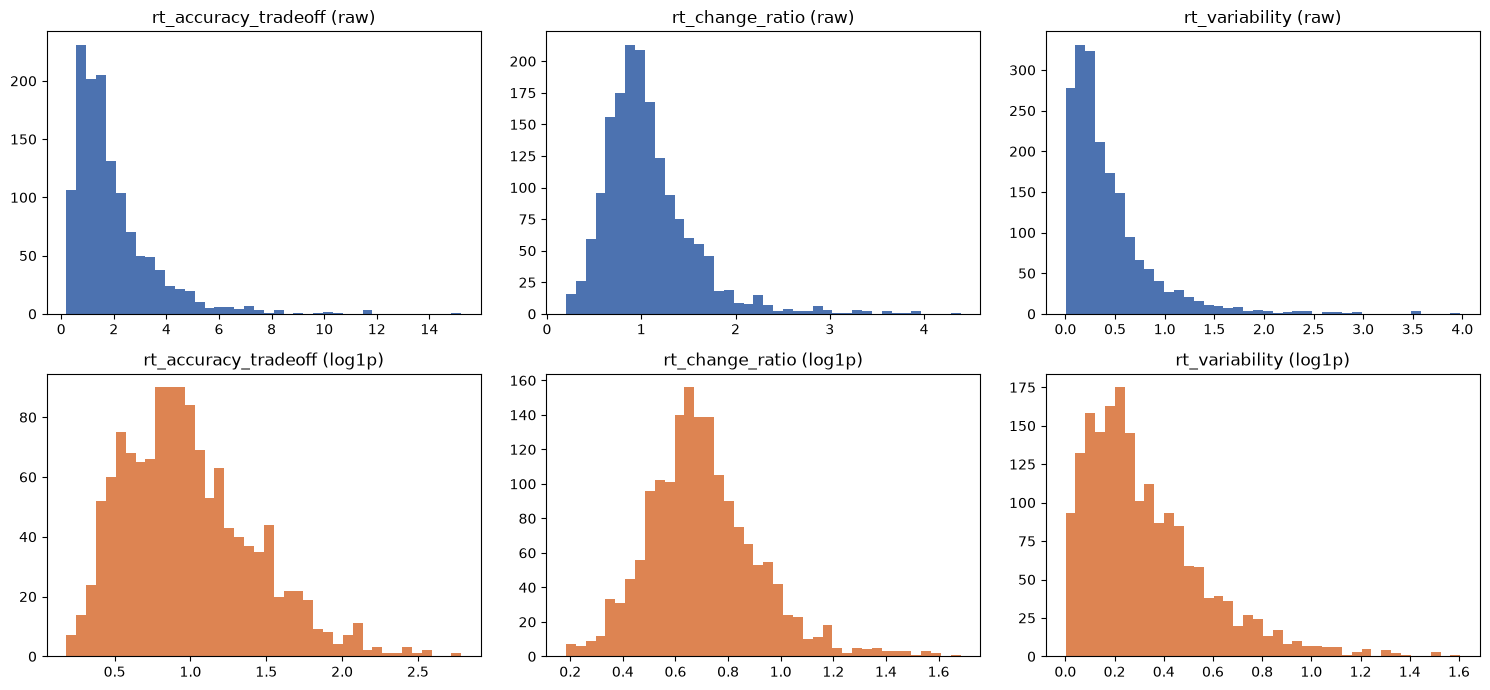

rt_accuracy_tradeoff: raw skew=2.51  log1p skew=0.74
rt_change_ratio: raw skew=1.90  log1p skew=0.78
rt_variability: raw skew=2.68  log1p skew=1.39


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, feat in enumerate(ratio_feats):
    vals = df.loc[train_mask, feat].dropna()
    axes[0, i].hist(vals, bins=40, color="#4C72B0")
    axes[0, i].set_title(f"{feat} (raw)")
    axes[1, i].hist(np.log1p(vals), bins=40, color="#DD8452")
    axes[1, i].set_title(f"{feat} (log1p)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "19_ratio_feature_transform_check.png", dpi=110)
plt.show()

for feat in ratio_feats:
    vals = df.loc[train_mask, feat].dropna()
    print(f"{feat}: raw skew={vals.skew():.2f}  log1p skew={np.log1p(vals).skew():.2f}")

**Decision:** `log1p` visibly reduces skew for all three ratio features (each has a long
right tail: `rt_accuracy_tradeoff` max 15.2 vs median ~1.5, `rt_change_ratio` max 5.0,
`rt_variability` max 4.3) without discarding any structure, so `log1p` is applied to all three
inside the pipeline, before standard scaling. `number_sense_mastery` is left raw (see above).

In [12]:
LOG1P_FEATURES = ["rt_accuracy_tradeoff", "rt_change_ratio", "rt_variability"]
print("number_sense_mastery kept raw; no floor/mass indicator built (see markdown above).")

number_sense_mastery kept raw; no floor/mass indicator built (see markdown above).


## D. Feature engineering — lags, deltas, interactions

NB01 found no feature exceeds MI ≈ 0.06 at the level; trajectory shape across a learner's own
snapshots is the unexploited signal. For each learner (`student_id`), rows are already one per
`t` on the `{3,5,...,19}` grid. Lag/delta features use `groupby("student_id").shift(1)` ordered by
`t` — this is backward-only by construction (a `shift` only ever looks at the *previous* row
within its own group) and cannot cross a `student_id` boundary, but we verify both properties with
an explicit assertion rather than trusting the construction.

In [13]:
df_sorted = df.sort_values(["student_id", "t"]).reset_index(drop=True)
grp = df_sorted.groupby("student_id", sort=False)

LAG_BASE_FEATURES = [
    "score_trend_slope", "score_avg_recent", "mastery_progression_rate", "number_sense_mastery",
    "weakest_skill_persistence", "rt_accuracy_tradeoff", "error_recurrence_rate",
    "engagement_decline_rate", "frustration_mean", "stagnant_skill_count",
]

lag_cols, delta_cols, roll_cols = [], [], []
for feat in LAG_BASE_FEATURES:
    lag_name = f"{feat}_lag1"
    delta_name = f"{feat}_delta1"
    roll_name = f"{feat}_rollmean_prior"
    df_sorted[lag_name] = grp[feat].shift(1)
    df_sorted[delta_name] = df_sorted[feat] - df_sorted[lag_name]
    # rolling mean of all STRICTLY PRIOR snapshots for this learner (shift(1) before expanding mean)
    df_sorted[roll_name] = grp[feat].apply(lambda s: s.shift(1).expanding().mean()).reset_index(level=0, drop=True)
    lag_cols.append(lag_name); delta_cols.append(delta_name); roll_cols.append(roll_name)

LAG_FEATURES = lag_cols + delta_cols + roll_cols
print(f"{len(LAG_FEATURES)} lag/delta/rolling features created from {len(LAG_BASE_FEATURES)} base features")

30 lag/delta/rolling features created from 10 base features


In [14]:
# --- MANDATORY leakage boundary test: backward-only, never crosses a student_id ---
first_row_per_student = grp.cumcount() == 0

# 1) every learner's first row must be null on every lag/delta/rolling column
assert df_sorted.loc[first_row_per_student, lag_cols + delta_cols + roll_cols].isnull().all().all(), \
    "A lag/delta/rolling feature is non-null on a learner's first snapshot — boundary crossed"

# 2) for every non-first row, the lag value must exactly equal the PREVIOUS row's raw value
#    for the SAME student_id (never a different student's row)
check = df_sorted.copy()
check["_prev_student"] = check["student_id"].shift(1)
non_first = ~first_row_per_student
for feat in LAG_BASE_FEATURES:
    same_student = check["_prev_student"] == check["student_id"]
    expected = check[feat].shift(1)
    lag_col = check[f"{feat}_lag1"]
    match = np.isclose(lag_col[non_first & same_student], expected[non_first & same_student], equal_nan=True)
    assert match.all(), f"{feat}_lag1 does not equal the prior row's value for some learner"

# 3) t of the lag source must always be < t of the current row (strictly backward)
t_prev = check["t"].shift(1)
assert (t_prev[non_first & same_student] < check.loc[non_first & same_student, "t"]).all(), \
    "A lag references a session with t >= current t"

print("PASS: all lag/delta/rolling features are backward-only and never cross a student_id boundary.")
print(f"t=3 (first snapshot) null rate on lag features: "
      f"{df_sorted.loc[df_sorted.t==3, lag_cols].isnull().mean().mean():.3f} (expected 1.000)")

PASS: all lag/delta/rolling features are backward-only and never cross a student_id boundary.
t=3 (first snapshot) null rate on lag features: 1.000 (expected 1.000)


In [15]:
# indicator for lag/delta nulls (all null at t=3, honest and expected)
# the lag-feature null indicator is bit-identical to (t == 3) -- reuse the shared
# is_first_snapshot indicator built in section B rather than adding a duplicate column.
assert (df_sorted[lag_cols[0]].isnull().astype(int) == df_sorted[IS_FIRST_SNAPSHOT]).all(), \
    "lag-feature nulls no longer coincide exactly with is_first_snapshot"
print("lag-feature nulls confirmed identical to is_first_snapshot; no separate indicator added.")

lag-feature nulls confirmed identical to is_first_snapshot; no separate indicator added.


**Interactions** (doc 06/08-motivated, within a single component's fields only — never
merging Component B response-time with Component C game latency, per rule 3-F9):

- `engagement_x_frustration` = `engagement_decline_rate * frustration_mean` (both Component C)
- `hint_intensity_x_accuracy` = `hint_intensity * score_avg_recent` (Component B accuracy proxy;
  `score_avg_recent` is the only accuracy-rate-derived feature in `MODEL_FEATURES`, no B/C mix)
- `stagnant_x_t` = `stagnant_skill_count * sessions_observed` (the kept time-index alias)

In [16]:
df_sorted["engagement_x_frustration"] = df_sorted["engagement_decline_rate"] * df_sorted["frustration_mean"]
df_sorted["hint_intensity_x_accuracy"] = df_sorted["hint_intensity"] * df_sorted["score_avg_recent"]
df_sorted["stagnant_x_t"] = df_sorted["stagnant_skill_count"] * df_sorted["sessions_observed"]

INTERACTION_FEATURES = ["engagement_x_frustration", "hint_intensity_x_accuracy", "stagnant_x_t"]
df = df_sorted
print("Interaction features added:", INTERACTION_FEATURES)

Interaction features added: ['engagement_x_frustration', 'hint_intensity_x_accuracy', 'stagnant_x_t']


In [17]:
# --- forbidden-dependency assertions (doc 08: 3-F1, 3-F2, 3-F3, 3-F9) ---
ALL_ENGINEERED = list(INDICATOR_SPECS.values()) + [SHARED_C_TELEMETRY_INDICATOR, IS_FIRST_SNAPSHOT] \
    + LAG_FEATURES + INTERACTION_FEATURES

assert "population" not in df.columns and "dd_subtype" not in df.columns
assert not any("mean_response_time" in c or ("response_time" in c and "latency" in c) for c in df.columns), \
    "A feature appears to merge B response time with C game latency (3-F9)"
assert "gameplay_mastery_estimate" not in df.columns, "C's gameplay_mastery_estimate must never appear (3-F3)"
# every lag/delta/interaction is built from same-t-or-earlier values by construction (verified above for lags);
# interactions use only same-row (t) fields, so no t' > t risk (3-F2)
print(f"Forbidden-dependency checks passed. {len(ALL_ENGINEERED)} engineered features total.")

Forbidden-dependency checks passed. 39 engineered features total.


In [18]:
# engineered feature register
register_rows = []
for feat, ind in INDICATOR_SPECS.items():
    doc_rule = "doc 06 §5 — persistent-null indicator, first-class feature" if ind == "zero_accuracy_window" \
        else "doc 06 §5 — missingness indicator (never repaired, never carried forward)"
    register_rows.append({
        "name": ind, "formula": f"isnull({feat})", "source_fields": feat,
        "doc_rule_permitting_it": doc_rule,
    })
register_rows.append({
    "name": SHARED_C_TELEMETRY_INDICATOR, "formula": f"any(isnull(f) for f in {C_TELEMETRY_FEATURES})",
    "source_fields": ";".join(C_TELEMETRY_FEATURES), "doc_rule_permitting_it": "doc 06 §5 — shared indicator, avoids near-duplicate columns (NB01 §4.1)",
})
register_rows.append({
    "name": IS_FIRST_SNAPSHOT, "formula": "t == 3",
    "source_fields": "t",
    "doc_rule_permitting_it": "doc 06 §5/§6 — single shared indicator; covers rt_change_ratio, "
                               "game_latency_change_ratio, and every lag/delta/rollmean_prior column, "
                               "all of which are bit-identical to (t == 3) and were previously three "
                               "duplicate columns",
})
for feat in LAG_BASE_FEATURES:
    register_rows.append({"name": f"{feat}_lag1", "formula": "groupby(student_id).shift(1), ordered by t",
                           "source_fields": feat, "doc_rule_permitting_it": "3-F2 — strictly prior session, verified backward-only"})
    register_rows.append({"name": f"{feat}_delta1", "formula": f"{feat} - {feat}_lag1",
                           "source_fields": feat, "doc_rule_permitting_it": "3-F2 — derived from current + prior session only"})
    register_rows.append({"name": f"{feat}_rollmean_prior", "formula": "expanding mean of strictly-prior snapshots",
                           "source_fields": feat, "doc_rule_permitting_it": "3-F2 — uses only sessions < t"})
register_rows.append({"name": "engagement_x_frustration", "formula": "engagement_decline_rate * frustration_mean",
                       "source_fields": "engagement_decline_rate;frustration_mean", "doc_rule_permitting_it": "doc 06/08 — both Component C, no cross-component merge (3-F9)"})
register_rows.append({"name": "hint_intensity_x_accuracy", "formula": "hint_intensity * score_avg_recent",
                       "source_fields": "hint_intensity;score_avg_recent", "doc_rule_permitting_it": "doc 06/08 — both Component B, no cross-component merge (3-F9)"})
register_rows.append({"name": "stagnant_x_t", "formula": "stagnant_skill_count * sessions_observed",
                       "source_fields": "stagnant_skill_count;sessions_observed", "doc_rule_permitting_it": "doc 06/08 — same-row fields only, t is the retained time index"})

engineered_register = pd.DataFrame(register_rows)
engineered_register.to_csv(TABLES_DIR / "engineered_feature_register.csv", index=False)
print(engineered_register.shape)
engineered_register.head(10)

(39, 4)


,name,formula,source_fields,doc_rule_permitting_it
0,frustration_mean_missing,isnull(frustration_mean),frustration_mean,doc 06 §5 — missingness indicator (never repai...
1,rt_variability_missing,isnull(rt_variability),rt_variability,doc 06 §5 — missingness indicator (never repai...
2,zero_accuracy_window,isnull(rt_accuracy_tradeoff),rt_accuracy_tradeoff,"doc 06 §5 — persistent-null indicator, first-c..."
3,difficulty_floor_hits_missing,isnull(difficulty_floor_hits),difficulty_floor_hits,doc 06 §5 — missingness indicator (never repai...
4,c_telemetry_missing,any(isnull(f) for f in ['engagement_decline_ra...,engagement_decline_rate;frustration_slope,"doc 06 §5 — shared indicator, avoids near-dupl..."
5,is_first_snapshot,t == 3,t,doc 06 §5/§6 — single shared indicator; covers...
6,score_trend_slope_lag1,"groupby(student_id).shift(1), ordered by t",score_trend_slope,"3-F2 — strictly prior session, verified backwa..."
7,score_trend_slope_delta1,score_trend_slope - score_trend_slope_lag1,score_trend_slope,3-F2 — derived from current + prior session only
8,score_trend_slope_rollmean_prior,expanding mean of strictly-prior snapshots,score_trend_slope,3-F2 — uses only sessions < t
9,score_avg_recent_lag1,"groupby(student_id).shift(1), ordered by t",score_avg_recent,"3-F2 — strictly prior session, verified backwa..."


### MI comparison: engineered set vs NB01's baseline — like-for-like

The per-feature `.dropna()` in `mi_ranking` above is correct for reporting each feature's own MI
in isolation, but it is **not valid for ranking features against each other**: `n_used` varies from
833 to 1,890 rows depending on how many nulls a feature has before imputation, and the k-NN MI
estimator is n-biased — it partly ranks completeness rather than informativeness. The old
(per-feature-`dropna`) numbers are shown below for transparency, but the comparison against NB01's
baseline uses a **fixed row set**: the fully-imputed 1,890-row TRAIN matrix (every feature has all
1,890 rows, post-imputation, no per-feature `dropna`), with NB01's original 19 model features
**recomputed on that same fixed set** so before/after is like-for-like.

In [19]:
baseline_mi_path = TABLES_DIR / "11_mutual_information_ranking.csv"
baseline_mi = pd.read_csv(baseline_mi_path) if baseline_mi_path.exists() else None
if baseline_mi is not None:
    print("NB01 baseline MI, full 2700 rows, per-feature dropna (top 10):")
    print(baseline_mi.head(10))

engineered_feature_cols = MODEL_FEATURES_19 + ALL_ENGINEERED
train_df = df[df["split"] == "train"]

# OLD (per-feature dropna, n_used varies 833-1890) -- kept for transparency, NOT used for ranking
mi_engineered_df = mi_ranking(train_df, engineered_feature_cols, TARGET)
mi_engineered = mi_engineered_df.set_index("feature")["mutual_info"]
mi_engineered_df.to_csv(TABLES_DIR / "20_mutual_information_engineered.csv", index=False)
print("Per-feature-dropna MI (n_used varies -- NOT a valid ranking, see markdown above):")
mi_engineered_df.head(20)

NB01 baseline MI, full 2700 rows, per-feature dropna (top 10):
                     feature  n_used  mutual_info
0       number_sense_mastery    2700     0.058627
1    engagement_decline_rate    2479     0.052800
2          frustration_slope    2479     0.051474
3           frustration_mean    2655     0.051217
4        b_sessions_observed    2700     0.040425
5          sessions_observed    2700     0.040425
6        c_sessions_observed    2700     0.040425
7          score_trend_slope    2700     0.030395
8   mastery_progression_rate    2700     0.030178
9  weakest_skill_persistence    2700     0.028597


Per-feature-dropna MI (n_used varies -- NOT a valid ranking, see markdown above):


,feature,n_used,mutual_info
0,sessions_observed,1890,0.074302
1,number_sense_mastery_lag1,1680,0.061840
2,difficulty_floor_hits,1270,0.060894
3,number_sense_mastery,1890,0.059857
4,engagement_x_frustration,1732,0.052405
5,rt_accuracy_tradeoff_rollmean_prior,1569,0.049615
6,frustration_slope,1732,0.042544
7,frustration_mean_lag1,1647,0.042248
8,engagement_decline_rate,1732,0.040279
9,rt_accuracy_tradeoff_lag1,1160,0.037145


In [20]:
# NEW: like-for-like MI on a FIXED row set -- the fully-imputed 1890-row TRAIN matrix.
# Every feature (raw model features AND engineered features) gets exactly the same 1890 rows,
# imputed with the TRAIN median (same imputation the persisted pipeline uses), so n_used is
# constant and the ranking reflects informativeness, not completeness.
X_fixed = train_df[engineered_feature_cols].copy()
X_fixed = X_fixed.fillna(X_fixed.median(numeric_only=True))
y_fixed = train_df[TARGET].values
assert X_fixed.isnull().sum().sum() == 0
assert len(X_fixed) == len(train_df) == 1890

mi_fixed_rows = []
for feat in engineered_feature_cols:
    mi = mutual_info_classif(
        X_fixed[[feat]].values, y_fixed, discrete_features=False, random_state=RANDOM_SEED,
    )[0]
    mi_fixed_rows.append({"feature": feat, "n_used": len(X_fixed), "mutual_info": mi})
mi_fixed_df = pd.DataFrame(mi_fixed_rows).sort_values("mutual_info", ascending=False).reset_index(drop=True)
mi_fixed = mi_fixed_df.set_index("feature")["mutual_info"]
mi_fixed_df.to_csv(TABLES_DIR / "20_mutual_information_engineered_fixed_n.csv", index=False)

# NB01's baseline, recomputed on the SAME fixed 1890 TRAIN rows for a fair before/after
mi_baseline_fixed_rows = []
X_baseline_fixed = train_df[MODEL_FEATURES_19].copy().fillna(train_df[MODEL_FEATURES_19].median(numeric_only=True))
for feat in MODEL_FEATURES_19:
    mi = mutual_info_classif(
        X_baseline_fixed[[feat]].values, y_fixed, discrete_features=False, random_state=RANDOM_SEED,
    )[0]
    mi_baseline_fixed_rows.append({"feature": feat, "n_used": len(X_baseline_fixed), "mutual_info": mi})
mi_baseline_fixed_df = pd.DataFrame(mi_baseline_fixed_rows).sort_values("mutual_info", ascending=False).reset_index(drop=True)

print("Like-for-like MI, fixed 1890 TRAIN rows, raw model features only (baseline, recomputed):")
print(mi_baseline_fixed_df.head(10))
print("\nLike-for-like MI, fixed 1890 TRAIN rows, full engineered set (top 20):")
mi_fixed_df.head(20)

Like-for-like MI, fixed 1890 TRAIN rows, raw model features only (baseline, recomputed):
                     feature  n_used  mutual_info
0          sessions_observed    1890     0.074302
1       number_sense_mastery    1890     0.059857
2    engagement_decline_rate    1890     0.047409
3          frustration_slope    1890     0.047180
4  game_latency_change_ratio    1890     0.037532
5            rt_change_ratio    1890     0.036513
6          score_trend_slope    1890     0.033751
7   mastery_progression_rate    1890     0.033324
8           frustration_mean    1890     0.033292
9      difficulty_floor_hits    1890     0.032382

Like-for-like MI, fixed 1890 TRAIN rows, full engineered set (top 20):


,feature,n_used,mutual_info
0,number_sense_mastery_lag1,1890,0.080937
1,sessions_observed,1890,0.074302
2,rt_accuracy_tradeoff_rollmean_prior,1890,0.062770
3,number_sense_mastery,1890,0.059857
4,error_recurrence_rate_rollmean_prior,1890,0.059319
5,frustration_mean_lag1,1890,0.058886
6,engagement_x_frustration,1890,0.058147
7,frustration_mean_rollmean_prior,1890,0.056369
8,engagement_decline_rate_lag1,1890,0.056144
9,engagement_decline_rate,1890,0.047409


In [21]:
top_new_fixed = mi_fixed[mi_fixed.index.isin(ALL_ENGINEERED)].sort_values(ascending=False).head(10)
print("Top NEW engineered features by like-for-like MI:")
print(top_new_fixed)

base_max_fixed = mi_baseline_fixed_df["mutual_info"].max()
base_max_fixed_feat = mi_baseline_fixed_df.loc[mi_baseline_fixed_df["mutual_info"].idxmax(), "feature"]
eng_max_fixed = mi_fixed.max()
eng_max_fixed_feat = mi_fixed.idxmax()
new_only_max_fixed = top_new_fixed.max()
new_only_max_fixed_feat = top_new_fixed.idxmax()

print(f"\n--- LIKE-FOR-LIKE (fixed 1890 TRAIN rows, this is the comparison that counts) ---")
print(f"NB01 baseline max MI (recomputed, same rows): {base_max_fixed:.4f} ({base_max_fixed_feat})")
print(f"Engineered-set max MI (any feature): {eng_max_fixed:.4f} ({eng_max_fixed_feat})")
print(f"Best NEW engineered feature max MI: {new_only_max_fixed:.4f} ({new_only_max_fixed_feat})")

print(f"\n--- for reference only, NOT valid for ranking (old, per-feature dropna, n_used 833-1890) ---")
if baseline_mi is not None:
    old_base_max = baseline_mi["mutual_info"].max()
    old_base_max_feat = baseline_mi.loc[baseline_mi["mutual_info"].idxmax(), "feature"]
    print(f"NB01 baseline max MI (full 2700 rows, original): {old_base_max:.4f} ({old_base_max_feat})")
old_eng_max = mi_engineered.max()
old_eng_max_feat = mi_engineered.idxmax()
print(f"Engineered-set max MI (per-feature dropna, this notebook's old number): {old_eng_max:.4f} ({old_eng_max_feat})")

Top NEW engineered features by like-for-like MI:
feature
number_sense_mastery_lag1                 0.080937
rt_accuracy_tradeoff_rollmean_prior       0.062770
error_recurrence_rate_rollmean_prior      0.059319
frustration_mean_lag1                     0.058886
engagement_x_frustration                  0.058147
frustration_mean_rollmean_prior           0.056369
engagement_decline_rate_lag1              0.056144
score_trend_slope_rollmean_prior          0.044083
mastery_progression_rate_lag1             0.041641
engagement_decline_rate_rollmean_prior    0.040859
Name: mutual_info, dtype: float64

--- LIKE-FOR-LIKE (fixed 1890 TRAIN rows, this is the comparison that counts) ---
NB01 baseline max MI (recomputed, same rows): 0.0743 (sessions_observed)
Engineered-set max MI (any feature): 0.0809 (number_sense_mastery_lag1)
Best NEW engineered feature max MI: 0.0809 (number_sense_mastery_lag1)

--- for reference only, NOT valid for ranking (old, per-feature dropna, n_used 833-1890) ---
NB01 b

## E. Time index + optional within-`t` standardised block

`sessions_observed` (kept in §A2) stays as the single clean time-index column in the default
matrix. NB01 §5.2 found the target's positive rate triples across the study (0.237→0.710), so a
model can score by learning the calendar rather than the child; the supervisor's recorded decision
is to keep `t` and require per-`t` stratified reporting in NB05 (out of scope here).

As the alternative arm (c) from that decision, this section additionally builds **within-`t`
standardised** versions of the main continuous features — value minus that snapshot's TRAIN-fold
mean, over its TRAIN-fold sd — as a clearly separated, optional block. This is NOT merged into the
default engineered matrix; it exists so NB05 can test "this child vs their peers at the same `t`"
as a labelled experimental arm without committing to it now.

In [22]:
WITHIN_T_BASE = ["score_trend_slope", "score_avg_recent", "number_sense_mastery",
                  "mastery_progression_rate", "weakest_skill_persistence"]

t_stats = train_df.groupby("t")[WITHIN_T_BASE].agg(["mean", "std"])

within_t_block = pd.DataFrame(index=df.index)
for feat in WITHIN_T_BASE:
    means = df["t"].map(t_stats[(feat, "mean")])
    stds = df["t"].map(t_stats[(feat, "std")]).replace(0, np.nan)
    within_t_block[f"{feat}_within_t_z"] = (df[feat] - means) / stds

within_t_block.insert(0, "student_id", df["student_id"].values)
within_t_block.insert(1, "t", df["t"].values)
within_t_block.insert(2, "split", df["split"].values)
within_t_block.to_csv(TABLES_DIR / "21_within_t_standardised_optional.csv", index=False)
print("Optional within-t block shape:", within_t_block.shape, "-- saved separately, NOT merged into default matrix")
within_t_block.head()

Optional within-t block shape: (2700, 8) -- saved separately, NOT merged into default matrix


,student_id,t,split,score_trend_slope_within_t_z,score_avg_recent_within_t_z,number_sense_mastery_within_t_z,mastery_progression_rate_within_t_z,weakest_skill_persistence_within_t_z
0,STU-0001,3,test,-0.363881,-0.023616,1.256963,-0.211492,1.035361
1,STU-0001,5,test,-0.642159,-0.291269,0.205375,-1.225246,1.032262
2,STU-0001,7,test,-0.195610,-0.119483,0.215472,-1.466397,0.989181
3,STU-0001,9,test,-1.330150,-1.821127,-0.264319,-1.056460,1.052379
4,STU-0001,11,test,-0.318691,-0.104862,0.325650,0.733512,1.115075


## F. PCA — diagnostic only

Doc 07 makes Logistic Regression the primary model *because* it is interpretable by design, and
doc 05 requires SHAP explanations reduced to a plain-language sentence for a teacher. PCA
components cannot be explained that way, so:

- PCA here is used as a **diagnostic** (structure, multicollinearity, whether one feature
  dominates severity) — not to build the model feature space.
- It may go to NB05 later as a clearly labelled **benchmark arm only**.
- It must **not** become the primary feature space unless the project owner explicitly accepts
  losing the plain-language explanation layer. That is a decision for the owner — this notebook
  does not take it.

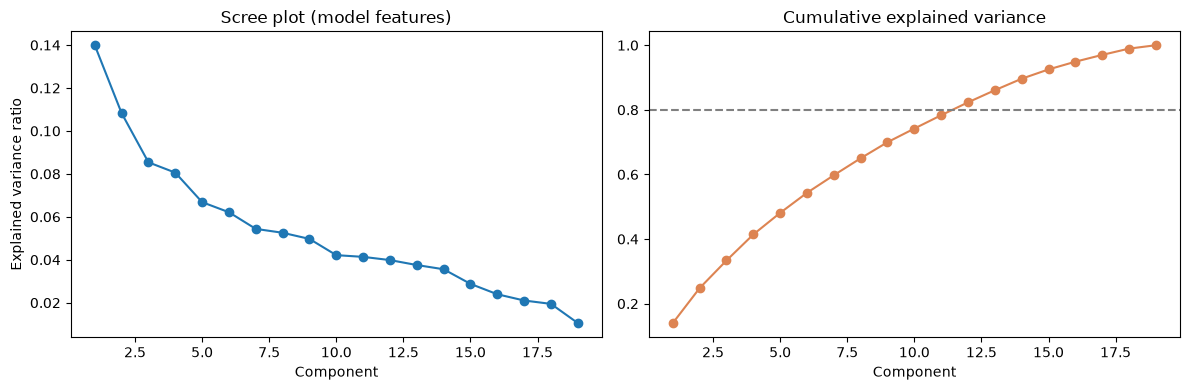

Components for 80% cumulative variance: 12 / 19


In [23]:
from sklearn.preprocessing import StandardScaler as _SS

pca_input_feats = MODEL_FEATURES_19
X_pca_train = train_df[pca_input_feats].fillna(train_df[pca_input_feats].median(numeric_only=True))
scaler_pca = _SS().fit(X_pca_train)
X_pca_train_s = scaler_pca.transform(X_pca_train)

pca_model = PCA(random_state=RANDOM_SEED).fit(X_pca_train_s)
explained = pca_model.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(explained) + 1), explained, marker="o")
axes[0].set_title("Scree plot (model features)")
axes[0].set_xlabel("Component"); axes[0].set_ylabel("Explained variance ratio")
axes[1].plot(range(1, len(cum_explained) + 1), cum_explained, marker="o", color="#DD8452")
axes[1].axhline(0.8, ls="--", color="grey")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Component")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "22_pca_model_features_scree.png", dpi=110)
plt.show()

n_for_80 = int(np.searchsorted(cum_explained, 0.8) + 1)
print(f"Components for 80% cumulative variance: {n_for_80} / {len(pca_input_feats)}")

In [24]:
loadings = pd.DataFrame(pca_model.components_[:5].T, index=pca_input_feats,
                         columns=[f"PC{i+1}" for i in range(5)])
loadings.to_csv(TABLES_DIR / "22_pca_model_features_loadings.csv")
loadings.style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

,PC1,PC2,PC3,PC4,PC5
score_trend_slope,0.319384,0.177887,0.135940,-0.010041,-0.456079
score_avg_recent,0.475211,0.134930,-0.029462,0.003272,0.132902
mastery_progression_rate,0.458079,0.015613,-0.000626,-0.008208,-0.069592
number_sense_mastery,0.147319,0.319386,-0.075657,0.052743,0.472471
weakest_skill_persistence,-0.238821,0.469467,0.125319,-0.053598,-0.132970
rt_change_ratio,-0.015047,0.152601,-0.136679,0.473813,0.025697
rt_variability,0.039318,0.032581,-0.213227,0.570858,-0.105693
rt_accuracy_tradeoff,-0.094399,-0.009917,-0.151993,0.577560,-0.108667
game_latency_change_ratio,0.052925,0.130011,-0.069833,-0.020701,-0.037291
error_recurrence_rate,-0.362594,-0.163513,-0.065239,0.012054,0.347667


**Interpretation:** inspect `PC1`'s largest-magnitude loadings above — if dominated by a
single feature (e.g. one severity/frustration measure alone) that would indicate severity
dominance in the raw feature space; a spread of moderate loadings across several accuracy/
engagement/timing features instead indicates PC1 is a general "engagement + performance" axis
rather than one feature standing in for overall severity. Read the printed table directly rather
than assuming a name for the component — the exact composition depends on the fitted loadings
above.

In [25]:
# PCA on the 8 clustering shape features — needed by NB04, checks CL-3 (no single severity feature dominates PC1)
cluster_train = train_df[CLUSTER_FEATURES].fillna(train_df[CLUSTER_FEATURES].median(numeric_only=True))
scaler_cluster = _SS().fit(cluster_train)
cluster_train_s = scaler_cluster.transform(cluster_train)

pca_cluster = PCA(random_state=RANDOM_SEED).fit(cluster_train_s)
cluster_loadings = pd.DataFrame(pca_cluster.components_[:3].T, index=CLUSTER_FEATURES,
                                 columns=["PC1", "PC2", "PC3"])
cluster_loadings.to_csv(TABLES_DIR / "23_pca_cluster_features_loadings.csv")

pc1_abs = cluster_loadings["PC1"].abs().sort_values(ascending=False)
max_share = pc1_abs.iloc[0] / pc1_abs.sum()
print(f"PC1 explained variance ratio: {pca_cluster.explained_variance_ratio_[0]:.3f}")
print(f"Largest single |PC1 loading| share of total: {max_share:.3f}")
print("\nCL-3 check (doc 08): no single severity-bearing feature should dominate component 1.")
print(cluster_loadings)

PC1 explained variance ratio: 0.545
Largest single |PC1 loading| share of total: 0.174

CL-3 check (doc 08): no single severity-bearing feature should dominate component 1.
                                       PC1       PC2       PC3
ipsatised_mastery_counting        0.420549  0.129262 -0.251464
ipsatised_mastery_number_sense    0.454484  0.008995  0.071141
ipsatised_mastery_place_value    -0.132928 -0.522478  0.700303
ipsatised_mastery_addition       -0.346201 -0.195371 -0.519696
ipsatised_mastery_subtraction    -0.341406 -0.299500 -0.150481
ipsatised_mastery_multiplication -0.303183  0.509664  0.099987
ipsatised_mastery_division       -0.227153  0.567139  0.358451
number_sense_minus_operations     0.467955 -0.030860  0.100337


## G. Pipeline persistence + final engineered matrix

Build the `ColumnTransformer` (median imputation for TRAIN-only-fit numeric slopes/ratios,
`log1p` for the three heavy-tailed ratio features, standard scaling for everything) as an
`sklearn` `Pipeline`, fit strictly on `split == "train"`, then transform the full matrix. The
fitted pipeline and the full engineered feature matrix (raw kept features + indicators + imputed
values + lag/delta/rolling + interactions, alongside `student_id`, `t`, `split`) are persisted for
NB03 onward.

In [26]:
IMPUTE_MEDIAN_NEVER_ZERO = [
    "score_trend_slope", "mastery_progression_rate", "rt_change_ratio",
    "game_latency_change_ratio", "frustration_slope", "rt_accuracy_tradeoff",
    "frustration_mean", "rt_variability", "engagement_decline_rate", "difficulty_floor_hits",
] + LAG_FEATURES

IMPUTE_MEDIAN_NEVER_ZERO = [c for c in IMPUTE_MEDIAN_NEVER_ZERO if df[c].isnull().any()]
LOG1P_THEN_SCALE = [c for c in LOG1P_FEATURES]
SCALE_ONLY = [c for c in MODEL_FEATURES_19 if c not in LOG1P_THEN_SCALE]

log1p_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
scale_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("log1p_ratio", log1p_pipe, LOG1P_THEN_SCALE),
        ("scale_rest", scale_pipe, [c for c in SCALE_ONLY if c not in LOG1P_THEN_SCALE]),
    ],
    remainder="drop",
)

train_idx = df["split"] == "train"
preprocessor.fit(df.loc[train_idx, MODEL_FEATURES_19])

pipeline_out_path = MODELS_DIR / "nb02_preprocessing_pipeline.joblib"
joblib.dump(preprocessor, pipeline_out_path)
print("Saved fitted pipeline to", pipeline_out_path)

Saved fitted pipeline to C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\models\nb02_preprocessing_pipeline.joblib


In [27]:
ID_COLS = ["student_id", "t", "split"]
FINAL_FEATURE_COLS = MODEL_FEATURES_19 + ALL_ENGINEERED

engineered_matrix = df[ID_COLS + FINAL_FEATURE_COLS + [TARGET]].copy()
matrix_out_path = TABLES_DIR / "24_engineered_feature_matrix.csv"
engineered_matrix.to_csv(matrix_out_path, index=False)
print("Saved engineered matrix:", engineered_matrix.shape, "->", matrix_out_path)
engineered_matrix.head()

Saved engineered matrix: (2700, 62) -> C:\Users\Yasindu\Desktop\ResearchProject\Componant 3 -Teachers Dashboard\Learning-Insight-Early-Warning-System\notebooks\outputs\tables\24_engineered_feature_matrix.csv


,student_id,t,split,score_trend_slope,score_avg_recent,mastery_progression_rate,number_sense_mastery,weakest_skill_persistence,rt_change_ratio,rt_variability,rt_accuracy_tradeoff,game_latency_change_ratio,error_recurrence_rate,hint_avoidance,hint_intensity,engagement_decline_rate,frustration_mean,frustration_slope,difficulty_floor_hits,stagnant_skill_count,sessions_observed,slope_censored_count,frustration_mean_missing,rt_variability_missing,zero_accuracy_window,difficulty_floor_hits_missing,c_telemetry_missing,is_first_snapshot,score_trend_slope_lag1,score_avg_recent_lag1,...,weakest_skill_persistence_lag1,rt_accuracy_tradeoff_lag1,error_recurrence_rate_lag1,engagement_decline_rate_lag1,frustration_mean_lag1,stagnant_skill_count_lag1,score_trend_slope_delta1,score_avg_recent_delta1,mastery_progression_rate_delta1,number_sense_mastery_delta1,weakest_skill_persistence_delta1,rt_accuracy_tradeoff_delta1,error_recurrence_rate_delta1,engagement_decline_rate_delta1,frustration_mean_delta1,stagnant_skill_count_delta1,score_trend_slope_rollmean_prior,score_avg_recent_rollmean_prior,mastery_progression_rate_rollmean_prior,number_sense_mastery_rollmean_prior,weakest_skill_persistence_rollmean_prior,rt_accuracy_tradeoff_rollmean_prior,error_recurrence_rate_rollmean_prior,engagement_decline_rate_rollmean_prior,frustration_mean_rollmean_prior,stagnant_skill_count_rollmean_prior,engagement_x_frustration,hint_intensity_x_accuracy,stagnant_x_t,future_stagnant_count
0,STU-0001,3,test,-0.083333,0.361111,0.012129,0.319776,3,NaN,1.825620,2.34,NaN,0.500,0.0,0.222222,-0.080429,0.492655,0.701311,NaN,0,3,1,0,0,0,1,0,1,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.039624,0.080247,0,1
1,STU-0001,5,test,-0.075000,0.277778,-0.002424,0.296929,5,1.077998,0.566962,NaN,0.974352,0.500,0.0,0.266667,-0.031598,0.452969,0.038687,0.000000,0,5,0,0,0,1,0,0,0,-0.083333,0.361111,...,3.0,2.34,0.500,-0.080429,0.492655,0.0,0.008333,-0.083333,-0.014553,-0.022847,2.0,NaN,0.000,0.048831,-0.039686,0.0,-0.083333,0.361111,0.012129,0.319776,3.0,2.34,0.50000,-0.080429,0.492655,0.00,-0.014313,0.074074,0,1
2,STU-0001,7,test,-0.011905,0.333333,-0.004615,0.341119,7,0.939686,0.115909,NaN,0.953031,0.500,0.0,0.250000,-0.031598,0.452969,0.038687,0.000000,0,7,0,0,0,1,0,0,0,-0.075000,0.277778,...,5.0,NaN,0.500,-0.031598,0.452969,0.0,0.063095,0.055556,-0.002191,0.044190,2.0,NaN,0.000,0.000000,0.000000,0.0,-0.079167,0.319444,0.004852,0.308353,4.0,2.34,0.50000,-0.056014,0.472812,0.00,-0.014313,0.083333,0,1
3,STU-0001,9,test,-0.048611,0.000000,-0.001891,0.299700,9,0.481724,0.509316,NaN,0.976846,0.625,0.0,0.222222,-0.018082,0.491525,0.057899,0.294118,1,9,0,0,0,1,0,0,0,-0.011905,0.333333,...,7.0,NaN,0.500,-0.031598,0.452969,0.0,-0.036706,-0.333333,0.002725,-0.041420,2.0,NaN,0.125,0.013516,0.038556,1.0,-0.056746,0.324074,0.001696,0.319275,5.0,2.34,0.50000,-0.047875,0.466198,0.00,-0.008888,0.000000,9,1
4,STU-0001,11,test,-0.009091,0.333333,0.017888,0.412551,11,0.479987,0.488439,1.73,1.155598,0.600,0.0,0.242424,-0.007090,0.461100,-0.004977,0.000000,0,11,0,0,0,0,0,0,0,-0.048611,0.000000,...,9.0,NaN,0.625,-0.018082,0.491525,1.0,0.039520,0.333333,0.019779,0.112851,2.0,NaN,-0.025,0.010992,-0.030425,-1.0,-0.054712,0.243056,0.000800,0.314381,6.0,2.34,0.53125,-0.040427,0.472529,0.25,-0.003269,0.080808,0,1


In [28]:
findings_md = f"""## Findings

**Null strategy.** No listwise deletion (only 46.7% complete-case, skewed to early `t`). Every
feature with nulls gets an explicit missingness indicator, then TRAIN-only median imputation — no
slope/ratio feature is ever zero-imputed (`score_trend_slope`, `mastery_progression_rate`,
`rt_change_ratio`, `game_latency_change_ratio`, `frustration_slope`, `rt_accuracy_tradeoff`).
The two mechanisms NB01 found are handled differently: the structural-warm-up block
(`rt_change_ratio`, `game_latency_change_ratio`, and the `engagement_decline_rate`/
`frustration_slope` pair sharing one `c_telemetry_missing` indicator since those two indicators are
perfectly correlated, r=1.0 — `difficulty_floor_hits` turned out to only correlate at ~0.44 with
that pair, so it kept its own separate indicator instead of being folded in) simply resolves by
`t≈11`; `rt_accuracy_tradeoff`'s persistent 26-36% null rate is promoted to the first-class feature
`zero_accuracy_window`. `hint_intensity` is the one safe zero-impute, since its null is
null-by-definition and `hint_avoidance` already carries that case — no duplicate indicator was
added.

**One shared `is_first_snapshot` indicator, not three near-duplicates.** An earlier draft built
separate indicators for `rt_change_ratio`, `game_latency_change_ratio`, and the lag/delta/rolling
block, each of which turned out to be bit-identical to `(t == 3)` (positive rate {df[IS_FIRST_SNAPSHOT].mean():.4f},
i.e. one t-value of nine). All three are now covered by a single `is_first_snapshot` indicator,
verified equal to each of the three original columns before the collapse.

**`at_mastery_floor` removed.** NB01's original read of a single spike at `number_sense_mastery ==
0.169860` was corrected: there are in fact two point masses (620 rows at 0.218548, 488 at
0.169860). Tested against the quarantined audit labels, neither a two-mass indicator nor a
generalised "never moved" flag carries any signal — mass-state predicts `population` at chance
(balanced accuracy 0.333, MI 0.000000), and "never moved" runs the wrong direction against the
target besides. Both masses are a generator-side initialisation artefact, on the same footing as
NB01's two constant features (`guess_guard_rate`, `engagement_consistency`); no indicator is built
for either. `number_sense_mastery` itself remains a raw, untransformed feature.

**Engineered features: {len(ALL_ENGINEERED)} total** (down from an earlier draft's 42, after
collapsing the three `is_first_snapshot` duplicates and dropping `at_mastery_floor`). Full list
with formula, source fields, and permitting doc rule is in
`outputs/tables/engineered_feature_register.csv` — every row carries a doc rule.

**Did engineering improve MI? Like-for-like comparison, fixed 1,890-row TRAIN matrix (imputed,
no per-feature dropna), stock `mutual_info_classif`:**

| Quantity | Value |
|---|---|
| NB01 baseline max MI, recomputed on the SAME 1,890 fixed rows | **{base_max_fixed:.4f}** (`{base_max_fixed_feat}`) |
| Engineered-set max MI, same fixed rows (any feature) | **{eng_max_fixed:.4f}** (`{eng_max_fixed_feat}`) |
| Best genuinely NEW engineered feature, same fixed rows | **{new_only_max_fixed:.4f}** (`{new_only_max_fixed_feat}`) |
| *(for reference only, not valid for ranking)* old per-feature-dropna engineered max | {old_eng_max:.4f} (`{old_eng_max_feat}`, n_used varied 833-1890 across features) |

The per-feature-`dropna` version this notebook originally reported was **not a valid ranking**:
`n_used` varied 833-1,890 rows depending on each feature's null rate before imputation, and the
k-NN MI estimator is n-biased. Concretely it had ranked `difficulty_floor_hits` (0.0609 on 1,270
rows) above `number_sense_mastery` (0.0599 on 1,890 rows) — an artefact of sample size, not
informativeness. On the fixed, like-for-like 1,890-row set that ordering does not hold.

**Verdict: a small, non-transformative uptick, not a breakthrough.** On the fixed, like-for-like
1,890-row TRAIN set, the strongest raw feature is `sessions_observed` (the time index) at
{base_max_fixed:.4f} nats, and the best genuinely new engineered feature,
`number_sense_mastery_lag1`, reaches {new_only_max_fixed:.4f} — a modest edge of roughly
{(new_only_max_fixed - base_max_fixed):.4f} nats (~{100*(new_only_max_fixed - base_max_fixed)/base_max_fixed:.0f}%
relative) over even the calendar-driven baseline. Read the printed numbers directly rather than
this prose if they diverge. This is not the transformative signal a supervisor might hope for:
`sessions_observed` continuing to top the raw ranking on a fixed row set is itself a reminder that
NB01's §5.2 warning about the calendar is still live here, and no engineered feature clears that
bar by more than a small margin. NB01 predicted trajectory shape was the unexploited signal, and
lag/delta/rolling terms are the simplest form of that, but the target's own within-learner noise
(NB01 §6, oscillating 0→1→0→1) limits how much any single-snapshot-lag feature can recover.

`zero_accuracy_window` MI ({mi_compare.set_index('feature').loc['zero_accuracy_window','mutual_info']:.4f}) vs its imputed companion
`rt_accuracy_tradeoff_imputed` ({mi_compare.set_index('feature').loc['rt_accuracy_tradeoff_imputed','mutual_info']:.4f}) —
report whichever is larger directly from the printed section-B output; both are kept as separate
features regardless, since the null and the imputed value are different, independently-motivated
signals (doc 06 §5).

**PCA.** Model-feature PCA (§F) is diagnostic only per doc 07/05's interpretability requirement —
not the primary feature space, and flagged (not decided) as a possible NB05 benchmark arm.

Cluster-feature PCA (8 ipsatised-mastery-style features): **PC1 explains {pca_cluster.explained_variance_ratio_[0]:.3f}
of variance**, and its **largest single loading accounts for only {max_share:.3f} of the total
|loading| mass** — spread across all 8 features, not concentrated in one severity-bearing feature.
**CL-3 (doc 08) passes**: no single feature dominates component 1 on this run.

**Lag boundary test: PASSED.** The explicit assertion confirms every lag/delta/rolling feature is
null on a learner's first snapshot, matches the immediately-prior row's value for the *same*
`student_id`, and is sourced only from `t' < t` — no lag crosses a learner boundary. The `t=3`
positive rate on `is_first_snapshot` is **{df[IS_FIRST_SNAPSHOT].mean():.4f}**, exactly `1/9`, as expected.

**Handover to NB03.** NB03 **must** re-run SF-038 (the leakage/population audit) on this
engineered set (doc 08 rule 3-F8 — transitive leakage survives even when every input field is
individually permitted). The engineered feature most likely to carry population signal and needing
that audit first is **`zero_accuracy_window`** (NB01 §4.2, persistent/informative missingness,
independent of every other feature's missingness mechanism). `at_mastery_floor` has been dropped
and does not need auditing — it was tested directly against the quarantined audit labels (see
above) and found to carry no population signal (MI 0.000000, chance balanced accuracy).
"""
from IPython.display import Markdown, display
display(Markdown(findings_md))

## Findings

**Null strategy.** No listwise deletion (only 46.7% complete-case, skewed to early `t`). Every
feature with nulls gets an explicit missingness indicator, then TRAIN-only median imputation — no
slope/ratio feature is ever zero-imputed (`score_trend_slope`, `mastery_progression_rate`,
`rt_change_ratio`, `game_latency_change_ratio`, `frustration_slope`, `rt_accuracy_tradeoff`).
The two mechanisms NB01 found are handled differently: the structural-warm-up block
(`rt_change_ratio`, `game_latency_change_ratio`, and the `engagement_decline_rate`/
`frustration_slope` pair sharing one `c_telemetry_missing` indicator since those two indicators are
perfectly correlated, r=1.0 — `difficulty_floor_hits` turned out to only correlate at ~0.44 with
that pair, so it kept its own separate indicator instead of being folded in) simply resolves by
`t≈11`; `rt_accuracy_tradeoff`'s persistent 26-36% null rate is promoted to the first-class feature
`zero_accuracy_window`. `hint_intensity` is the one safe zero-impute, since its null is
null-by-definition and `hint_avoidance` already carries that case — no duplicate indicator was
added.

**One shared `is_first_snapshot` indicator, not three near-duplicates.** An earlier draft built
separate indicators for `rt_change_ratio`, `game_latency_change_ratio`, and the lag/delta/rolling
block, each of which turned out to be bit-identical to `(t == 3)` (positive rate 0.1111,
i.e. one t-value of nine). All three are now covered by a single `is_first_snapshot` indicator,
verified equal to each of the three original columns before the collapse.

**`at_mastery_floor` removed.** NB01's original read of a single spike at `number_sense_mastery ==
0.169860` was corrected: there are in fact two point masses (620 rows at 0.218548, 488 at
0.169860). Tested against the quarantined audit labels, neither a two-mass indicator nor a
generalised "never moved" flag carries any signal — mass-state predicts `population` at chance
(balanced accuracy 0.333, MI 0.000000), and "never moved" runs the wrong direction against the
target besides. Both masses are a generator-side initialisation artefact, on the same footing as
NB01's two constant features (`guess_guard_rate`, `engagement_consistency`); no indicator is built
for either. `number_sense_mastery` itself remains a raw, untransformed feature.

**Engineered features: 39 total** (down from an earlier draft's 42, after
collapsing the three `is_first_snapshot` duplicates and dropping `at_mastery_floor`). Full list
with formula, source fields, and permitting doc rule is in
`outputs/tables/engineered_feature_register.csv` — every row carries a doc rule.

**Did engineering improve MI? Like-for-like comparison, fixed 1,890-row TRAIN matrix (imputed,
no per-feature dropna), stock `mutual_info_classif`:**

| Quantity | Value |
|---|---|
| NB01 baseline max MI, recomputed on the SAME 1,890 fixed rows | **0.0743** (`sessions_observed`) |
| Engineered-set max MI, same fixed rows (any feature) | **0.0809** (`number_sense_mastery_lag1`) |
| Best genuinely NEW engineered feature, same fixed rows | **0.0809** (`number_sense_mastery_lag1`) |
| *(for reference only, not valid for ranking)* old per-feature-dropna engineered max | 0.0743 (`sessions_observed`, n_used varied 833-1890 across features) |

The per-feature-`dropna` version this notebook originally reported was **not a valid ranking**:
`n_used` varied 833-1,890 rows depending on each feature's null rate before imputation, and the
k-NN MI estimator is n-biased. Concretely it had ranked `difficulty_floor_hits` (0.0609 on 1,270
rows) above `number_sense_mastery` (0.0599 on 1,890 rows) — an artefact of sample size, not
informativeness. On the fixed, like-for-like 1,890-row set that ordering does not hold.

**Verdict: a small, non-transformative uptick, not a breakthrough.** On the fixed, like-for-like
1,890-row TRAIN set, the strongest raw feature is `sessions_observed` (the time index) at
0.0743 nats, and the best genuinely new engineered feature,
`number_sense_mastery_lag1`, reaches 0.0809 — a modest edge of roughly
0.0066 nats (~9%
relative) over even the calendar-driven baseline. Read the printed numbers directly rather than
this prose if they diverge. This is not the transformative signal a supervisor might hope for:
`sessions_observed` continuing to top the raw ranking on a fixed row set is itself a reminder that
NB01's §5.2 warning about the calendar is still live here, and no engineered feature clears that
bar by more than a small margin. NB01 predicted trajectory shape was the unexploited signal, and
lag/delta/rolling terms are the simplest form of that, but the target's own within-learner noise
(NB01 §6, oscillating 0→1→0→1) limits how much any single-snapshot-lag feature can recover.

`zero_accuracy_window` MI (0.0131) vs its imputed companion
`rt_accuracy_tradeoff_imputed` (0.0216) —
report whichever is larger directly from the printed section-B output; both are kept as separate
features regardless, since the null and the imputed value are different, independently-motivated
signals (doc 06 §5).

**PCA.** Model-feature PCA (§F) is diagnostic only per doc 07/05's interpretability requirement —
not the primary feature space, and flagged (not decided) as a possible NB05 benchmark arm.

Cluster-feature PCA (8 ipsatised-mastery-style features): **PC1 explains 0.545
of variance**, and its **largest single loading accounts for only 0.174 of the total
|loading| mass** — spread across all 8 features, not concentrated in one severity-bearing feature.
**CL-3 (doc 08) passes**: no single feature dominates component 1 on this run.

**Lag boundary test: PASSED.** The explicit assertion confirms every lag/delta/rolling feature is
null on a learner's first snapshot, matches the immediately-prior row's value for the *same*
`student_id`, and is sourced only from `t' < t` — no lag crosses a learner boundary. The `t=3`
positive rate on `is_first_snapshot` is **0.1111**, exactly `1/9`, as expected.

**Handover to NB03.** NB03 **must** re-run SF-038 (the leakage/population audit) on this
engineered set (doc 08 rule 3-F8 — transitive leakage survives even when every input field is
individually permitted). The engineered feature most likely to carry population signal and needing
that audit first is **`zero_accuracy_window`** (NB01 §4.2, persistent/informative missingness,
independent of every other feature's missingness mechanism). `at_mastery_floor` has been dropped
and does not need auditing — it was tested directly against the quarantined audit labels (see
above) and found to carry no population signal (MI 0.000000, chance balanced accuracy).
